# 02 · Exploring the Lee County Single-Family Market

**Data:** 105k qualified single-family sales, 2019–2025, built in `01_build_dataset.ipynb`.

Questions this notebook answers before any predictive modeling:

1. What did the market do from 2019 to 2025, and how much of it was interest rates?
2. **Where** is housing expensive, and where is the flood risk?
3. Which features actually add value, once you stop comparing apples to oranges?
4. What did Hurricane Ian change: who sold, at what price, and does the data support a causal design for Part 2?

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import hedonic as h
from plotting import *

use_style()
pd.set_option("display.width", 200)
FIG = ROOT / "figures"
SRC = "Source: Lee County Property Appraiser (SDF/NAL), Lee County GIS, FEMA."

sf = pd.read_parquet(ROOT / "data/processed/sales_sf.parquet")
undamaged = sf[~sf["damaged_sale"]]
print(f"{len(sf):,} sales  |  {sf['damaged_sale'].sum():,} sold storm-damaged  |  {sf['gis_matched'].mean():.1%} have map coordinates")

105,234 sales  |  3,238 sold storm-damaged  |  95.5% have map coordinates


## 1. The cycle: a boom, a rate shock, and a slow deflation

Three panels on a shared time axis rather than one chart with two y-axes; volume, price, and rates have
different units, and stacking them keeps each honest.

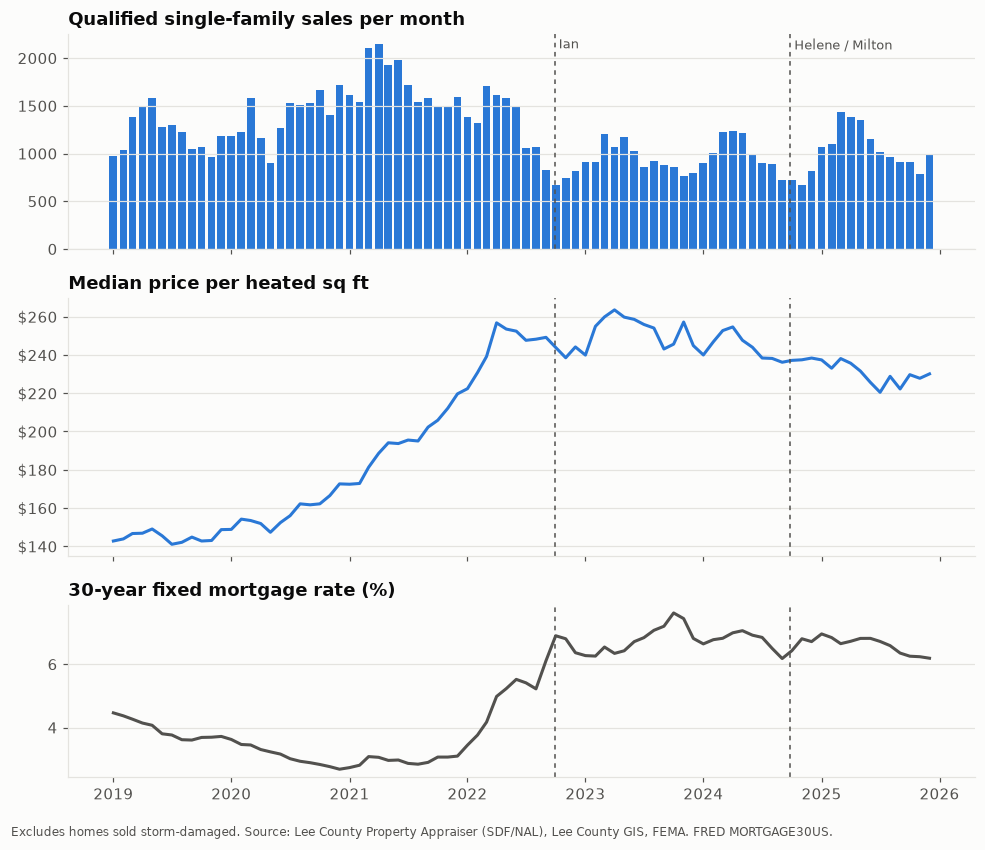

In [2]:
fred = pd.read_csv(ROOT / "data/raw/fred/MORTGAGE30US.csv", parse_dates=["observation_date"])
rate = fred.set_index("observation_date")["MORTGAGE30US"].resample("MS").mean()["2019":"2025"]

monthly = undamaged.groupby("sale_date").agg(sales=("sale_id", "size"), ppsf=("price_per_sqft", "median"))

fig, axes = plt.subplots(3, 1, figsize=(9, 7.5), sharex=True, gridspec_kw={"height_ratios": [1, 1.2, 0.8]})
axes[0].bar(monthly.index, monthly["sales"], width=24, color=C1)
axes[0].set_title("Qualified single-family sales per month")
axes[1].plot(monthly.index, monthly["ppsf"], color=C1)
axes[1].set_title("Median price per heated sq ft"); dollars(axes[1])
axes[2].plot(rate.index, rate, color=INK2)
axes[2].set_title("30-year fixed mortgage rate (%)")
for ax in axes:
    event(ax, "2022-09-28", "Ian" if ax is axes[0] else "", y=0.98)
    event(ax, "2024-09-26", "Helene / Milton" if ax is axes[0] else "", y=0.98)
year_axis(axes[2])
source_note(fig, "Excludes homes sold storm-damaged. " + SRC + " FRED MORTGAGE30US.")
save(fig, FIG / "02_market_cycle.png")

In [3]:
yr = undamaged.groupby("sale_yr").agg(sales=("sale_id", "size"), median_price=("sale_price", "median"),
                                      median_ppsf=("price_per_sqft", "median"))
yr["ppsf_vs_2019"] = yr["median_ppsf"] / yr.loc[2019, "median_ppsf"] - 1
yr.join(rate.groupby(rate.index.year).mean().rename("avg_rate")).style.format(
    {"sales": "{:,}", "median_price": "${:,.0f}", "median_ppsf": "${:,.0f}", "ppsf_vs_2019": "{:+.0%}", "avg_rate": "{:.2f}%"})

,sales,median_price,median_ppsf,ppsf_vs_2019,avg_rate
sale_yr,,,,,
2019,"14,530","$249,900",$145,+0%,3.93%
2020,"16,688","$280,000",$158,+9%,3.11%
2021,"20,731","$340,000",$194,+34%,2.96%
2022,"14,300","$415,000",$244,+68%,5.33%
2023,"11,369","$429,000",$254,+75%,6.80%
2024,"11,300","$415,000",$244,+68%,6.72%
2025,"13,078","$390,000",$231,+59%,6.60%


**Read:** prices rose ~70% from 2019 to the 2022–23 peak while rates sat near 3%. When rates doubled in 2022,
**volume** broke first (2021's record ~20k sales fell by almost half), then prices drifted down ~10% from peak.
Ian landed right on top of the rate shock. That's the core identification problem for Part 2: a simple
before/after comparison would blame the storm for what the Fed did. The fix is a comparison group that
experienced the same rates but not the same flood risk.

## 2. Where value and flood risk sit

To compare locations across years, each sale's $/sq ft is expressed **relative to the county median in its
sale quarter**, which strips out the cycle above. Hexagons show the median of that ratio (min. 5 sales).

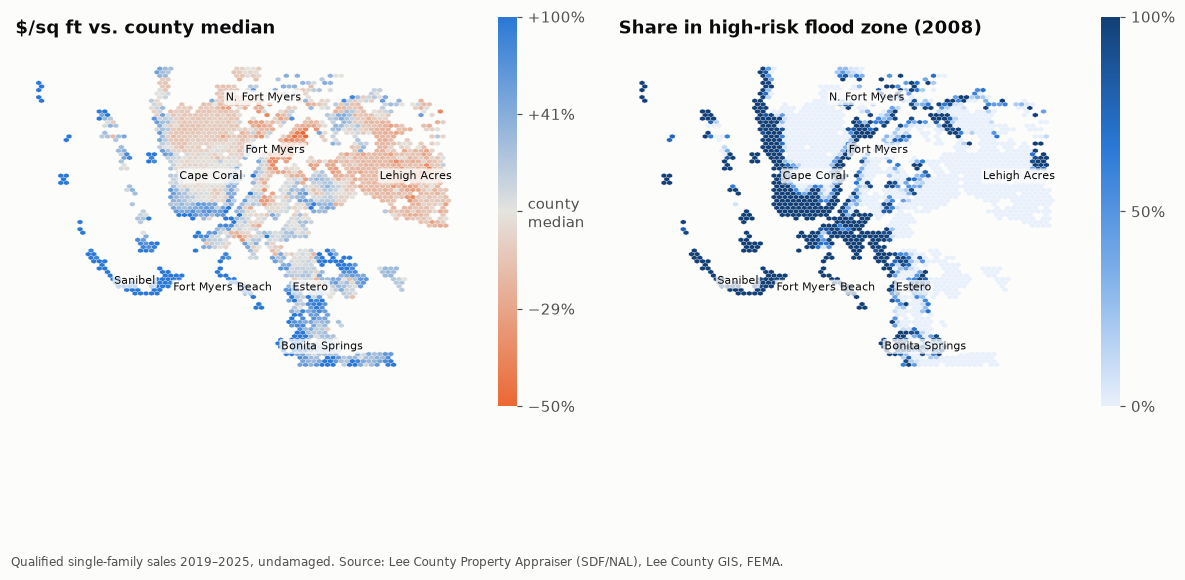

In [4]:
geo = undamaged[undamaged["gis_matched"]].copy()
q_med = geo.groupby(pd.Grouper(key="sale_date", freq="QS"))["price_per_sqft"].transform("median")
geo["rel_ppsf"] = np.log2(geo["price_per_sqft"] / q_med)

fig, axes = plt.subplots(1, 2, figsize=(11, 6.2))
aspect = 1 / np.cos(np.radians(26.6))   # degrees of longitude are shorter at this latitude
kw = dict(gridsize=75, mincnt=5, linewidths=0.15, edgecolors=SURFACE)

hb = axes[0].hexbin(geo["lon"], geo["lat"], C=geo["rel_ppsf"], reduce_C_function=np.median,
                    cmap=DIVERGING, norm=TwoSlopeNorm(0, -1, 1), **kw)
cb = fig.colorbar(hb, ax=axes[0], shrink=0.6, ticks=[-1, -0.5, 0, 0.5, 1])
cb.ax.set_yticklabels(["−50%", "−29%", "county\nmedian", "+41%", "+100%"]); cb.outline.set_visible(False)
axes[0].set_title("$/sq ft vs. county median")

hb2 = axes[1].hexbin(geo["lon"], geo["lat"], C=geo["sfha_2008"].astype(float), reduce_C_function=np.mean,
                     cmap=SEQUENTIAL, vmin=0, vmax=1, **kw)
cb2 = fig.colorbar(hb2, ax=axes[1], shrink=0.6, ticks=[0, .5, 1]); cb2.outline.set_visible(False)
cb2.ax.set_yticklabels(["0%", "50%", "100%"])
axes[1].set_title("Share in high-risk flood zone (2008)")

labels = {"Cape Coral": (-81.97, 26.60), "Lehigh Acres": (-81.62, 26.60), "Fort Myers": (-81.86, 26.64),
          "Sanibel": (-82.10, 26.44), "Fort Myers Beach": (-81.95, 26.43), "Bonita Springs": (-81.78, 26.34),
          "Estero": (-81.80, 26.43), "N. Fort Myers": (-81.88, 26.72)}
for ax in axes:
    ax.set_aspect(aspect); ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_visible(False)
    for name, (x, y) in labels.items():
        ax.annotate(name, (x, y), fontsize=7.5, color=INK, ha="center",
                    bbox=dict(boxstyle="round,pad=0.15", fc=SURFACE, ec="none", alpha=0.75))
source_note(fig, "Qualified single-family sales 2019–2025, undamaged. " + SRC)
save(fig, FIG / "02_maps_value_flood.png")

**Read:** the expensive hexagons (blue, left) line the Gulf coast, the islands, and the river; the
flood zone (right) covers almost the same places. Lehigh Acres, inland and almost entirely outside the flood
zone, is the cheapest market in the county. **High value and high flood risk are geographically the same
thing here**, which is why the raw flood-zone "premium" in notebook 01 is positive. Untangling the two is the
job of section 3.

### By city: boom and bust were not evenly shared

,sales,in_flood_zone,ppsf_2021,ppsf_2025,ppsf_change,volume_change
city,,,,,,
LEHIGH ACRES,"13,145",4%,$147,$204,+39%,-26%
ESTERO,"6,445",23%,$221,$290,+32%,-33%
BONITA SPRINGS,"7,493",29%,$256,$334,+31%,-34%
FORT MYERS,"28,918",36%,$189,$234,+24%,-42%
FORT MYERS BEACH,758,100%,$541,$642,+19%,-66%
NORTH FORT MYERS,"4,854",46%,$172,$198,+15%,-25%
ALVA,"1,258",14%,$186,$211,+13%,-23%
SAINT JAMES CITY,690,97%,$316,$356,+13%,-52%
CAPE CORAL,"34,956",42%,$199,$222,+12%,-36%


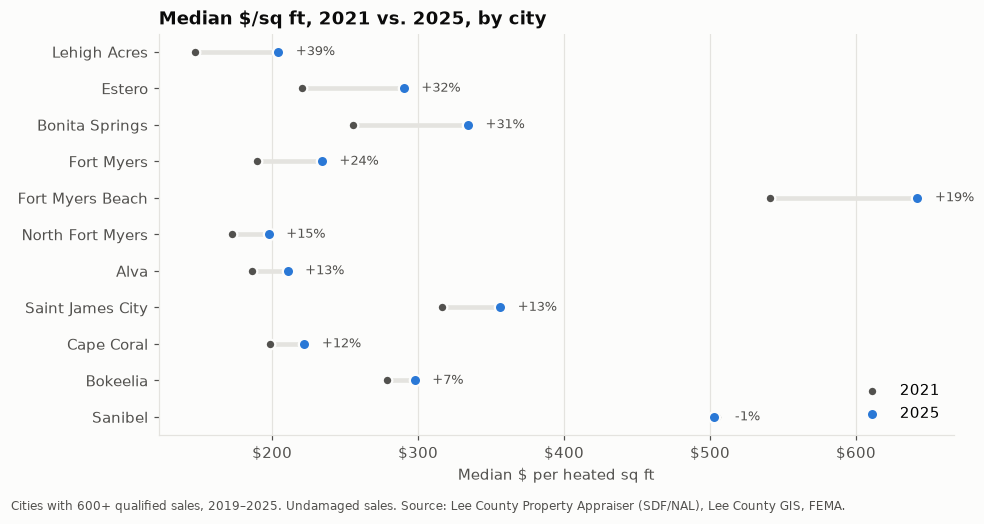

In [5]:
city = (undamaged.groupby("city")
        .apply(lambda g: pd.Series({
            "sales": len(g),
            "ppsf_2021": g.loc[g["sale_yr"] == 2021, "price_per_sqft"].median(),
            "ppsf_2025": g.loc[g["sale_yr"] == 2025, "price_per_sqft"].median(),
            "sales_2021": (g["sale_yr"] == 2021).sum(), "sales_2025": (g["sale_yr"] == 2025).sum(),
            "in_flood_zone": g["sfha_2008"].mean()}), include_groups=False)
        .query("sales >= 600"))
city["ppsf_change"] = city["ppsf_2025"] / city["ppsf_2021"] - 1
city["volume_change"] = city["sales_2025"] / city["sales_2021"] - 1
city = city.sort_values("ppsf_change")

fig, ax = plt.subplots(figsize=(9, 4.6))
y = np.arange(len(city))
ax.hlines(y, city["ppsf_2021"], city["ppsf_2025"], color=GRID, lw=3)
ax.scatter(city["ppsf_2021"], y, color=INK2, s=40, zorder=3, label="2021", edgecolor=SURFACE, lw=1.5)
ax.scatter(city["ppsf_2025"], y, color=C1, s=55, zorder=3, label="2025", edgecolor=SURFACE, lw=1.5)
for i, (name, r) in enumerate(city.iterrows()):
    ax.text(max(r["ppsf_2021"], r["ppsf_2025"]) + 12, i, f"{r['ppsf_change']:+.0%}", va="center", fontsize=8.5, color=INK2)
ax.set_yticks(y, city.index.str.title()); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
dollars(ax, "x"); ax.set_xlabel("Median $ per heated sq ft")
ax.set_title("Median $/sq ft, 2021 vs. 2025, by city")
ax.legend(loc="lower right")
source_note(fig, "Cities with 600+ qualified sales, 2019–2025. Undamaged sales. " + SRC)
save(fig, FIG / "02_cities_2021_vs_2025.png")

city[["sales", "in_flood_zone", "ppsf_2021", "ppsf_2025", "ppsf_change", "volume_change"]].sort_values("ppsf_change", ascending=False).style.format(
    {"sales": "{:,.0f}", "in_flood_zone": "{:.0%}", "ppsf_2021": "${:,.0f}", "ppsf_2025": "${:,.0f}",
     "ppsf_change": "{:+.0%}", "volume_change": "{:+.0%}"})

**Read:** the inland, affordable markets (Lehigh Acres, Estero, Bonita) gained the most since 2021. Sanibel, the
island Ian's surge hit hardest, is roughly flat in price, but that understates the damage: the comparison only
includes homes that sold **undamaged**, and the volume column shows how many fewer of those there are. That's
section 5's survivor-bias problem in miniature.

## 3. What actually adds value? Raw gaps vs. like-for-like comparisons

A pool home sells for far more than a home without one, but pool homes are also bigger, newer, and more often
on the water. To isolate each feature, fit a **hedonic regression**:

$$\log(\text{price}) = \beta \cdot \text{features} + \text{block group} + \text{sale month} + \varepsilon$$

- *features:* log heated sq ft, log lot acres, age (and age²), pool, boat dock, seawall, waterfront type, flood zone
- *block group fixed effect:* compares homes only to others in the same Census block group (~740 small areas)
- *sale-month fixed effect:* compares homes sold in the same month, so the market cycle drops out

**Why block groups and not the appraiser's neighborhood codes?** The appraiser draws neighborhoods by
waterfront type: only **2%** of sales are in a neighborhood that mixes waterfront types, vs. 86% for block
groups. Neighborhood controls would erase exactly the variation we want to measure. (`src/hedonic.py`
absorbs the 740 block-group dummies by de-meaning, which gives identical coefficients much faster.)

In [6]:
mix = pd.DataFrame({fe: {
    "groups": sf[fe].nunique(),
    "sales in groups mixing waterfront types": (sf.groupby(fe)["waterfront"].transform("nunique") > 1).mean(),
    "sales in groups mixing flood-zone status": (sf.groupby(fe)["sfha_2008"].transform("nunique") > 1).mean()}
    for fe in ["neighborhood", "block_group", "market_area"]}).T
mix.style.format({"groups": "{:,.0f}", "sales in groups mixing waterfront types": "{:.0%}",
                  "sales in groups mixing flood-zone status": "{:.0%}"})

,groups,sales in groups mixing waterfront types,sales in groups mixing flood-zone status
neighborhood,"1,993",2%,27%
block_group,740,86%,41%
market_area,35,100%,90%


In [7]:
WF = ["NONE", "LAKE", "GOLF", "CANAL", "CREEK", "RIVER", "BAY", "GULF"]

def prep(df):
    df = df[df["gis_matched"]].copy()
    df["log_heated"], df["log_acres"] = np.log(df["heated_area"]), np.log(df["acres"])
    df["age"], df["age2"] = df["age_at_sale"], df["age_at_sale"] ** 2 / 100
    for c in ["pool", "boat_dock", "seawall"]:
        df[c] = df[c].astype(float)
    df["flood_zone"] = df["sfha_2008"].astype(float)
    df["wf"] = pd.Categorical(df["waterfront"], categories=WF)
    return df

u = prep(undamaged)
X = h.design(u, ["log_heated", "log_acres", "age", "age2", "pool", "boat_dock", "seawall", "flood_zone"], ["wf"])
fit = h.absorb_ols(u["log_price"], X, u["block_group"])
print(f"n = {int(fit.nobs):,}   within-block-group R² = {fit.rsquared:.3f}")
print(f"Size elasticity: +10% heated sq ft -> {100*(1.1**fit.params['log_heated']-1):+.1f}% price;  "
      f"+10% lot -> {100*(1.1**fit.params['log_acres']-1):+.1f}%")

terms = ["pool", "boat_dock", "seawall", "flood_zone"] + [f"wf_{w}" for w in WF[1:]]
prem = h.premiums(fit, terms)
raw = {c: u.loc[u[c] == 1, "sale_price"].median() / u.loc[u[c] == 0, "sale_price"].median() - 1
       for c in ["pool", "boat_dock", "seawall", "flood_zone"]}
raw |= {f"wf_{w}": u.loc[u["waterfront"] == w, "sale_price"].median() / u.loc[u["waterfront"] == "NONE", "sale_price"].median() - 1
        for w in WF[1:]}
prem["raw_pct"] = 100 * pd.Series(raw)
prem["n_homes"] = [int(u[c].sum()) if c in u else int((u["waterfront"] == c[3:]).sum()) for c in prem.index]
prem.index = (prem.index.str.replace("wf_", "Waterfront: ").str.replace("_", " ").str.title()
                    .str.replace("Flood Zone", "In flood zone (SFHA)"))
prem.round(1)

n = 97,248   within-block-group R² = 0.742
Size elasticity: +10% heated sq ft -> +5.9% price;  +10% lot -> +1.6%


,premium_pct,lo_pct,hi_pct,raw_pct,n_homes
Pool,18.5,17.7,19.2,68.4,43576
Boat Dock,3.7,2.1,5.3,53.7,8875
Seawall,18.9,14.8,23.2,65.3,13077
In flood zone (SFHA),0.5,-1.6,2.5,26.9,35352
Waterfront: Lake,7.1,5.9,8.4,49.8,15761
Waterfront: Golf,10.4,7.4,13.5,67.3,5076
Waterfront: Canal,15.4,11.9,19.1,75.2,12561
Waterfront: Creek,12.2,6.7,17.9,62.5,295
Waterfront: River,64.1,55.1,73.5,234.6,558
Waterfront: Bay,51.8,34.1,71.9,217.7,324


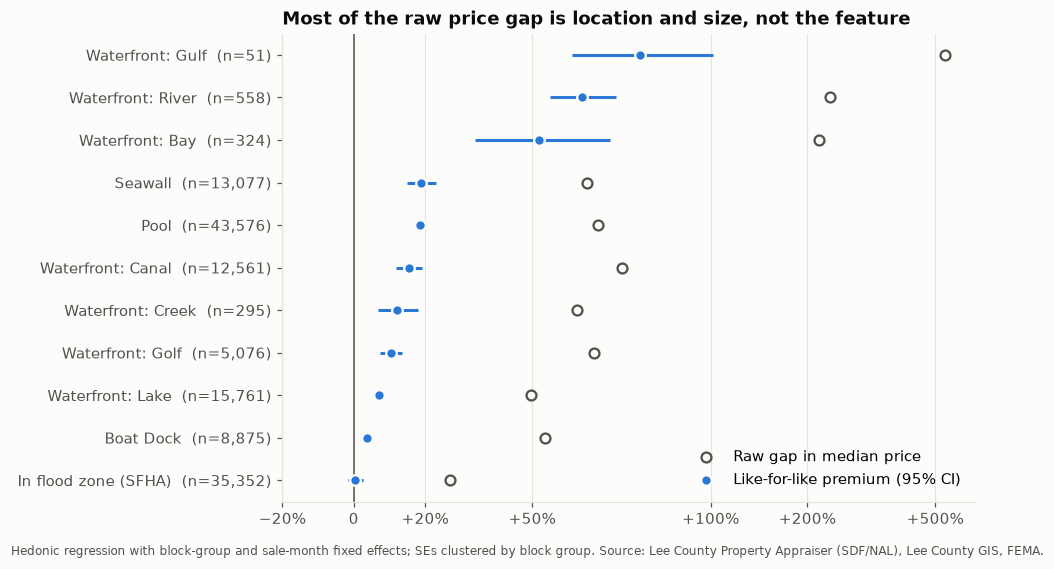

In [8]:
p = prem.sort_values("premium_pct")
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(p))
ax.hlines(y, p["lo_pct"], p["hi_pct"], color=C1, lw=2)
ax.scatter(p["raw_pct"], y, marker="o", s=42, facecolor=SURFACE, edgecolor=INK2, lw=1.5, zorder=3,
           label="Raw gap in median price")
ax.scatter(p["premium_pct"], y, s=48, color=C1, edgecolor=SURFACE, lw=1.5, zorder=4,
           label="Like-for-like premium (95% CI)")
ax.set_xscale("symlog", linthresh=100)
ax.set_xticks([-20, 0, 20, 50, 100, 200, 500], ["−20%", "0", "+20%", "+50%", "+100%", "+200%", "+500%"])
ax.axvline(0, color=INK2, lw=1)
ax.set_yticks(y, [f"{i}  (n={n:,})" for i, n in zip(p.index, p["n_homes"])])
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Most of the raw price gap is location and size, not the feature")
ax.legend(loc="lower right")
source_note(fig, "Hedonic regression with block-group and sale-month fixed effects; SEs clustered by block group. " + SRC)
save(fig, FIG / "02_raw_vs_controlled_premiums.png")

**Read:**
- **Pools** look like +68% in raw medians, but add about **+18%** like-for-like, still the biggest single
  amenity in Southwest Florida.
- **Boat docks** collapse from +54% to about **+4%**. A dock mostly signals *being on a navigable canal*;
  the canal itself carries the value.
- **Flood zone**, holding waterfront and location fixed, is **~0%** across the whole 2019–2025 period. Buyers
  were paying for the water, not discounting the risk. Section 5 asks whether that changed after Ian.
- **Direct water** is the largest effect: open Gulf (+80%), river (+64%), and bay (+52%) frontage vs.
  canal (+15%) and lake (+7%). Gulf has only ~50 sales, hence the wide interval.
- Size: +10% heated sq ft ≈ +6% price; the rest of the value is land and location.

This is also a preview of Part 1: a linear model with these features already explains ~74% of the price
variation *within* block groups.

## 4. Waterfront and flood zone overlap, but not completely

For a flood-zone comparison to work, there must be homes with the **same** waterfront type on both sides of
the flood-zone line. Share of each waterfront type inside the 2008 high-risk zone:

In [9]:
wf_tab = sf.groupby("waterfront").agg(sales=("sale_id", "size"), in_flood_zone=("sfha_2008", "mean"))
wf_tab.loc[WF].style.format({"sales": "{:,}", "in_flood_zone": "{:.0%}"})

,sales,in_flood_zone
waterfront,,
NONE,"64,207",32%
LAKE,"15,944",31%
GOLF,"5,178",34%
CANAL,"13,690",70%
CREEK,327,91%
RIVER,670,94%
BAY,381,98%
GULF,63,100%


Bay, Gulf, river, and creek homes are almost all in the flood zone, so they have no comparison group and the
DiD can't learn from them on their own. **Canal, lake, golf, and non-waterfront homes appear on both sides of
the line** (31–70% inside), and that's where Part 2's identification comes from: two similar canal homes a
few blocks apart, one mapped high-risk in 2008 and one not.

## 5. What Ian changed

### 5a. Survivor bias: the hardest-hit homes sell under a different code

After Ian, homes sold **as-is with storm damage** are coded `qual_cd = 03` ("arm's-length, but property changed")
with `sale_chg_cd = 5` (disaster), **not** 01. Phase 2's first draft kept only 01/02 and silently dropped them.
They're now kept and flagged `damaged_sale`. Why it matters:

In [10]:
post = sf[sf["post_ian"] & (sf["sale_date"] < "2024-10-01")]   # Ian period, before Helene/Milton
t = post.groupby("sfha_2008").agg(sales=("sale_id", "size"), sold_damaged=("damaged_sale", "mean"))
t.index = ["outside flood zone", "in flood zone (2008 SFHA)"]
display(t.style.format({"sales": "{:,}", "sold_damaged": "{:.1%}"}))

dmg_city = (sf[sf["post_ian"]].groupby("city")["damaged_sale"].agg(["mean", "size"])
            .query("size >= 200").sort_values("mean", ascending=False).head(6))
dmg_city.columns = ["share sold damaged (post-Ian)", "post-Ian sales"]
dmg_city.style.format({"share sold damaged (post-Ian)": "{:.0%}", "post-Ian sales": "{:,}"})

,sales,sold_damaged
outside flood zone,"14,968",2.9%
in flood zone (2008 SFHA),"9,156",19.1%


,share sold damaged (post-Ian),post-Ian sales
city,,
FORT MYERS BEACH,53%,367
SANIBEL,38%,681
SAINT JAMES CITY,27%,300
BOKEELIA,13%,249
NORTH FORT MYERS,11%,"2,198"
FORT MYERS,7%,"11,567"


Damaged sales are concentrated **in the treatment group** (flood zone) and on the islands. Dropping them would
measure Ian's effect only on the homes that came through fine, biasing the estimate toward zero. Part 2 reports
both: the effect on undamaged homes (a pure *risk perception / insurance* effect) and on all homes.

### 5b. Preview of Part 2: did flood-zone homes lose value relative to comparable homes?

Same hedonic model, but the flood-zone indicator is interacted with six-month periods, anchored so the
first post-storm period starts **Oct 2022** (Ian made landfall Sept 28). The reference period is Apr–Sep 2022,
the last six months before the storm. Each point is the flood-zone price gap in that period minus the gap
just before Ian, holding size, age, amenities, waterfront type, block group, and sale month fixed.

start,2018-10-01,2019-04-01,2019-10-01,2020-04-01,2020-10-01,2021-04-01,2021-10-01,2022-10-01,2023-04-01,2023-10-01,2024-04-01,2024-10-01,2025-04-01,2025-10-01
undamaged only,0.8,0.0,1.3,1.4,2.4,2.5,1.9,-7.6,-4.4,-2.3,-3.0,-4.3,-4.8,-2.9
incl. damaged,0.9,0.1,1.4,1.5,2.4,2.3,2.1,-12.5,-6.9,-3.6,-3.4,-5.5,-5.5,-3.6


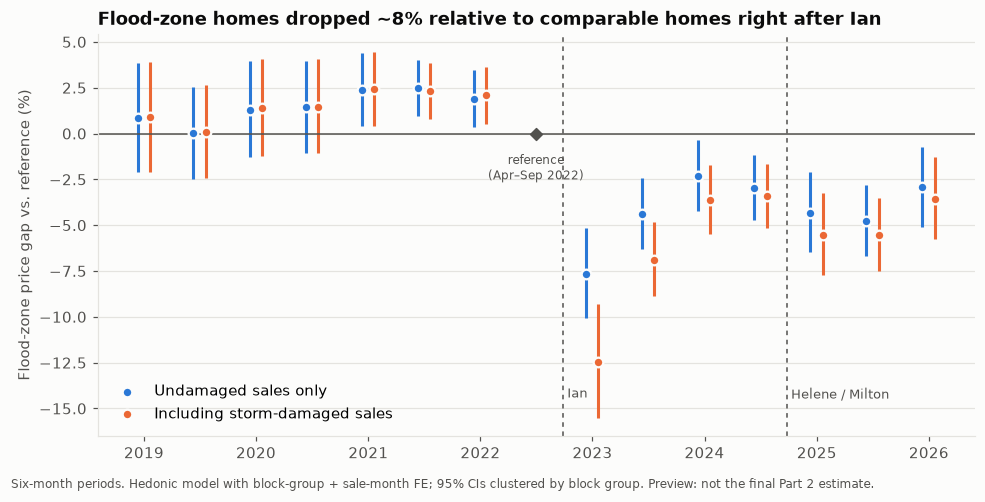

In [11]:
def event_study(df):
    df = prep(df)
    months = df["sale_date"].dt.year * 12 + df["sale_date"].dt.month - 1
    df["period"] = (months - (2022 * 12 + 9)) // 6           # 0 = Oct 2022 - Mar 2023
    periods = sorted(p for p in df["period"].unique() if p != -1)
    names = []
    for p in periods:
        names.append(f"fz_p{p}")
        df[names[-1]] = df["flood_zone"] * (df["period"] == p)
    X = h.design(df, ["log_heated", "log_acres", "age", "age2", "pool", "boat_dock", "seawall", "flood_zone"] + names, ["wf"])
    out = h.premiums(h.absorb_ols(df["log_price"], X, df["block_group"]), names)
    out["start"] = [pd.Timestamp("2022-10-01") + pd.DateOffset(months=6 * p) for p in periods]
    return out

es_u, es_all = event_study(undamaged), event_study(sf)

fig, ax = plt.subplots(figsize=(9, 4.4))
for es, label, color, dx in [(es_u, "Undamaged sales only", C1, -20), (es_all, "Including storm-damaged sales", C2, 20)]:
    x = es["start"] + pd.Timedelta(days=91 + dx)   # plot at period midpoint, offset to avoid overlap
    ax.vlines(x, es["lo_pct"], es["hi_pct"], color=color, lw=2)
    ax.scatter(x, es["premium_pct"], color=color, s=40, zorder=3, edgecolor=SURFACE, lw=1.5, label=label)
ax.scatter([pd.Timestamp("2022-07-01")], [0], marker="D", s=30, color=INK2, zorder=3)
ax.annotate("reference\n(Apr–Sep 2022)", (pd.Timestamp("2022-07-01"), 0), xytext=(0, -30),
            textcoords="offset points", ha="center", fontsize=8, color=INK2)
ax.axhline(0, color=INK2, lw=1)
event(ax, "2022-09-28", "Ian", y=0.12); event(ax, "2024-09-26", "Helene / Milton", y=0.12)
ax.set_ylabel("Flood-zone price gap vs. reference (%)")
ax.set_title("Flood-zone homes dropped ~8% relative to comparable homes right after Ian")
ax.legend(loc="lower left"); year_axis(ax)
source_note(fig, "Six-month periods. Hedonic model with block-group + sale-month FE; 95% CIs clustered by block group. Preview: not the final Part 2 estimate.")
save(fig, FIG / "02_preview_event_study.png")
pd.DataFrame({"undamaged only": es_u.set_index("start")["premium_pct"],
              "incl. damaged": es_all.set_index("start")["premium_pct"]}).round(1).T

**Read:**
- **Before Ian** the gap stays within about +2.5% of the reference for 3½ years. That's close to the flat
  **pre-trend** a difference-in-differences design needs (the two groups moving together before the
  storm), but not perfectly flat: flood-zone homes gained ~2% relative value in 2020–21, during the
  pandemic waterfront boom. Part 2 must check that this drift isn't driving the result (e.g., compare with
  the average of all pre-periods rather than one reference period, and add group-specific trends).
- **In the six months after Ian** flood-zone homes sold **~8% below** their pre-storm relative price, the
  clearest break in the series.
- **Afterwards** the gap partly recovers to about **−2% to −5%** and has not returned to zero by late 2025.
  Including storm-damaged sales shifts the estimates down, as section 5a predicted.
- The last point covers only Oct–Dec 2025 sales, hence the wider interval.

What this *doesn't* yet tell us: whether the drop is from flood **damage**, **insurance** costs (Florida
premiums and the new FEMA Risk Rating 2.0 both rose over this window), or **buyer perception**. Helene and Milton
(Sept/Oct 2024) also hit the post period. Part 2 will separate these where the data allows.

### 5c. Do newer building codes hold value better?

Florida adopted a statewide building code in **2002**, after Hurricane Andrew. If buyers learned from Ian that
construction quality matters, homes built under it should gain relative value afterwards.

In [12]:
u2 = prep(undamaged)
u2["post"] = u2["post_ian"].astype(float)
u2["built_2002_plus"] = (u2["year_built"] >= 2002).astype(float)
u2["built_2002_plus_x_post"] = u2["built_2002_plus"] * u2["post"]
u2["flood_zone_x_post"] = u2["flood_zone"] * u2["post"]
X = h.design(u2, ["log_heated", "log_acres", "age", "age2", "pool", "boat_dock", "seawall", "flood_zone",
                  "built_2002_plus", "built_2002_plus_x_post", "flood_zone_x_post"], ["wf"])
h.premiums(h.absorb_ols(u2["log_price"], X, u2["block_group"]), ["built_2002_plus_x_post", "flood_zone_x_post"]).round(1)

,premium_pct,lo_pct,hi_pct
built_2002_plus_x_post,2.6,1.5,3.6
flood_zone_x_post,-5.4,-6.7,-4.2


Post-2002 homes gained about **+2.6%** relative to older homes after Ian (same block group, size, and age
curve), a small but statistically clear "resilience premium." It's a candidate extension for Part 2:
did code-era homes in the flood zone lose less?

## 6. Takeaways and what they mean for the next phases

1. **2019–2025 was a rate-driven cycle**: +70% to peak, volume halved by the 2022 rate shock, ~10% off peak by 2025.
   Any Ian analysis needs a control group; time fixed effects alone won't cut it.
2. **Value and flood risk occupy the same coastline.** The raw flood-zone premium (+27%) is entirely
   waterfront and location; like-for-like it's ~0% before Ian.
3. **Raw amenity gaps are mostly confounding** (docks: +54% raw → +4% controlled). Part 1's model must use
   location carefully, and should use **block groups**, not appraiser neighborhoods, which are drawn by waterfront.
4. **The hardest-hit homes sell under qualification code 03.** Kept and flagged; excluding them causes survivor bias.
5. **Preview:** flood-zone homes sold **~8% below** comparable homes in the six months after Ian, recovering
   to a persistent **~2–5%** discount. The pre-trend is nearly but not perfectly flat (a ~2% pandemic-era drift),
   which Part 2 must handle. Post-2002 building-code homes gained ~2.6% relative value.

**Next, Phase 4 (Part 1): price model.** Predict single-family sale prices: linear hedonic baseline vs.
gradient-boosted trees, with a **time-based** train/test split (train on earlier sales, test on later ones) so
the score reflects real forecasting, and SHAP to explain what the model learned.